# Task 1 · Kobe: coach's reference solution

**Recipe:** 2-8-8-1 ReLU MLP (105 parameters, the largest legal size) on standardised inputs, `BCEWithLogitsLoss`, Adam with lr 1e-2 for 2,000 full-batch steps (a few seconds on one CPU thread). Then fold the standardisation into `fc1`, so that the saved model takes the raw coordinates the grader sends. The submission files go to `kobe_submission/`.

**What to expect:** "always miss" gets 0.553 and the accuracy ceiling for `(x, y)` is about 0.61. Any well-trained legal net lands at 0.60–0.61 on validation and 0.60–0.625 on the leaderboard (±0.01 noise from about 2,500 test shots per board).

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

torch.set_num_threads(1)  # a 105-parameter model gains nothing from more threads, and the machine is shared

DATA_DIR = Path("../data/kobe")  # Colab: upload data_train.csv to the Files panel and use Path(".")
SUB_DIR = Path("kobe_submission")  # the submission files are written here
SUB_DIR.mkdir(exist_ok=True)

df = pd.read_csv(DATA_DIR / "data_train.csv")
df.head()

,loc_x,loc_y,minutes_remaining,shot_distance,shot_made_flag,shot_id
0,0,0,7,0,1,1
1,-3,130,9,13,0,2
2,82,8,7,8,0,3
3,100,101,10,14,1,4
4,0,0,9,0,1,5


In [2]:
X = df[["loc_x", "loc_y"]].values.astype(np.float32)  # the ONLY legal inputs, in the units the grader sends
y = df["shot_made_flag"].values.astype(np.float32)
print(f"{len(df)} shots, {y.mean():.3f} of them made")
df[["loc_x", "loc_y"]].describe().round(1)

25000 shots, 0.447 of them made


,loc_x,loc_y
count,25000.0,25000.0
mean,7.1,91.3
std,110.0,88.3
min,-250.0,-44.0
25%,-67.2,4.0
50%,0.0,72.0
75%,94.0,160.0
max,248.0,791.0


In [3]:
from sklearn.model_selection import train_test_split

# stratify keeps the made-rate equal in both parts; random_state=0 gives everybody the same split
X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)
X_tr.shape, X_va.shape

((20000, 2), (5000, 2))

## Know the window before training

The labels are coin flips whose probability depends on where the shot was taken. Accuracy only asks on which side of 0.5 that probability lies, and only shots within about 3 ft of the rim go in more than half the time. So the accuracy-optimal classifier is close to "made iff within 3 ft", and that rule is the practical ceiling.

In [4]:
always_miss = (y_va == 0).mean()
r = np.hypot(X_va[:, 0], X_va[:, 1])  # distance to the rim in tenths of feet (analysis only, never a model input)
rim_rule = r <= 30
print(f"always miss:                      {always_miss:.4f}")
print(f"made iff within 3 ft of the rim:  {(rim_rule == y_va).mean():.4f}")

always miss:                      0.5526
made iff within 3 ft of the rim:  0.6022


## Model: written to the submission file, then imported

One class serves training and grading. `logits()` feeds `BCEWithLogitsLoss` during training; `forward()`, which the grader calls, adds the final Sigmoid. The Sigmoid has no parameters, so the state dict is the same either way.

In [5]:
%%writefile kobe_submission/submission_model.py
import torch
import torch.nn as nn


class MyModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(2, 8)
        self.act1 = nn.ReLU()
        self.fc2 = nn.Linear(8, 8)
        self.act2 = nn.ReLU()
        self.fc3 = nn.Linear(8, 1)
        self.out = nn.Sigmoid()  # the grader gets a probability, as in the official baseline

    def logits(self, x):  # used for training with nn.BCEWithLogitsLoss
        x = self.act1(self.fc1(x))
        x = self.act2(self.fc2(x))
        return self.fc3(x)

    def forward(self, x):  # what the grader calls
        return self.out(self.logits(x))

Overwriting kobe_submission/submission_model.py


In [6]:
import importlib.util


def load_model_class(path):
    # import MyModel from a .py file, the way the grader does
    spec = importlib.util.spec_from_file_location("submission_model", path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module.MyModel


MyModel = load_model_class(SUB_DIR / "submission_model.py")
model = MyModel()
print(model)
print("parameters:", sum(p.numel() for p in model.parameters()))

MyModel(
  (fc1): Linear(in_features=2, out_features=8, bias=True)
  (act1): ReLU()
  (fc2): Linear(in_features=8, out_features=8, bias=True)
  (act2): ReLU()
  (fc3): Linear(in_features=8, out_features=1, bias=True)
  (out): Sigmoid()
)
parameters: 105


In [7]:
ALLOWED = (nn.Linear, nn.ReLU, nn.Sigmoid, nn.Tanh, nn.ELU, nn.LeakyReLU, nn.PReLU)


def check_rules(model):
    layers = list(model.children())
    linears = [m for m in layers if isinstance(m, nn.Linear)]
    sizes_in = [m.in_features for m in linears]
    sizes_out = [m.out_features for m in linears]

    called = []  # the modules, in the order the forward pass uses them

    def record(module, inputs, output):
        called.append(module)

    hooks = [m.register_forward_hook(record) for m in layers]
    x = torch.tensor(X_va[:256])  # raw coordinates, as the grader sends them
    with torch.no_grad():
        out = model(x)
    for h in hooks:
        h.remove()

    # replay the forward pass with nothing but the recorded modules: any extra maths makes it differ
    replay_ok = True
    chained = x
    with torch.no_grad():
        try:  # an illegal model can crash here; that counts as a FAIL
            for m in called:
                chained = m(chained)
        except RuntimeError:
            replay_ok = False

    rules = {
        "no nn.Sequential / ModuleList / ModuleDict":
            not any(isinstance(m, (nn.Sequential, nn.ModuleList, nn.ModuleDict)) for m in model.modules()),
        "only nn.Linear and the allowed activations":
            all(isinstance(m, ALLOWED) for m in model.modules() if m is not model),
        "no parameters or buffers outside the layers":
            all("." in name for name in model.state_dict()),
        "at most 3 linear layers": len(linears) <= 3,
        "at most 8 neurons per linear layer": all(n <= 8 for n in sizes_out),
        "input size 2, sizes chain up, output size 1":
            sizes_in == [2] + sizes_out[:-1] and sizes_out[-1:] == [1],
        "every module used exactly once, the first is a linear layer":
            len(called) == len(set(called)) == len(layers) and isinstance(called[0], nn.Linear),
        "every activation comes right after a linear layer":
            all(isinstance(a, nn.Linear) for a, b in zip(called, called[1:]) if not isinstance(b, nn.Linear)),
        "forward is only these modules, no extra maths": replay_ok and torch.allclose(out, chained),
        "output shape (N, 1)": out.shape == (len(x), 1),
    }
    for rule, ok in rules.items():
        print("PASS" if ok else "FAIL", " ", rule)
    return all(rules.values())


check_rules(model)

PASS   no nn.Sequential / ModuleList / ModuleDict
PASS   only nn.Linear and the allowed activations
PASS   no parameters or buffers outside the layers
PASS   at most 3 linear layers
PASS   at most 8 neurons per linear layer
PASS   input size 2, sizes chain up, output size 1
PASS   every module used exactly once, the first is a linear layer
PASS   every activation comes right after a linear layer
PASS   forward is only these modules, no extra maths
PASS   output shape (N, 1)


True

## Standardise with training statistics

In [8]:
mu = X_tr.mean(axis=0)  # one value per column, from the training split only
sd = X_tr.std(axis=0)
print("mu", mu, " sd", sd)

X_tr_t = torch.tensor((X_tr - mu) / sd)
X_va_t = torch.tensor((X_va - mu) / sd)
y_tr_t = torch.tensor(y_tr)[:, None]  # (N, 1), like the model output
y_va_t = torch.tensor(y_va)[:, None]

mu [ 7.6579  90.88215]  sd [110.32168  88.47614]


## Train

In [9]:
torch.manual_seed(0)  # seeded only so that the printed numbers match the README
model = MyModel()
loss_fn = nn.BCEWithLogitsLoss()
opt = torch.optim.Adam(model.parameters(), lr=1e-2)  # 1e-3 is still under-trained after 2,000 steps
losses = []
for step in range(2000):  # full batch: all 20,000 training shots in every step
    opt.zero_grad()
    loss = loss_fn(model.logits(X_tr_t), y_tr_t)
    loss.backward()
    opt.step()
    losses.append(loss.item())
print(f"training BCE: step 0 {losses[0]:.4f}, last step {losses[-1]:.4f}   (best constant guess: 0.687)")

training BCE: step 0 0.6909, last step 0.6613   (best constant guess: 0.687)


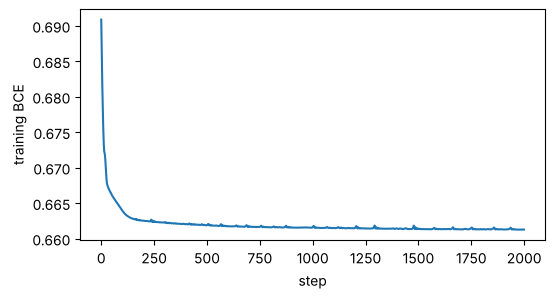

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 3))
plt.plot(losses)
plt.xlabel("step")
plt.ylabel("training BCE")
plt.show()

## Validate

In [11]:
model.eval()
with torch.no_grad():
    logits_va = model.logits(X_va_t)
    val_bce = loss_fn(logits_va, y_va_t).item()
    p_va = torch.sigmoid(logits_va)[:, 0].numpy()
pred = p_va > 0.5
print(f"validation BCE {val_bce:.4f}")
print(f"validation accuracy {(pred == y_va).mean():.4f}   (always miss {always_miss:.4f}, rim rule {(rim_rule == y_va).mean():.4f})")
print(f"predicted 'made' for {pred.mean():.3f} of the shots; agrees with the rim rule on {(pred == rim_rule).mean():.3f}")

validation BCE 0.6649
validation accuracy 0.6018   (always miss 0.5526, rim rule 0.6022)
predicted 'made' for 0.231 of the shots; agrees with the rim rule on 0.981


The net rediscovers the rim rule, which is the ceiling. Over five different random splits the same recipe averages about 0.607 (± 0.005); split 0 happens to be a slightly harder draw (the rim rule also gets only 0.602 on it).

What the net learned, drawn on the court (rim at (0, 0), y towards half court):

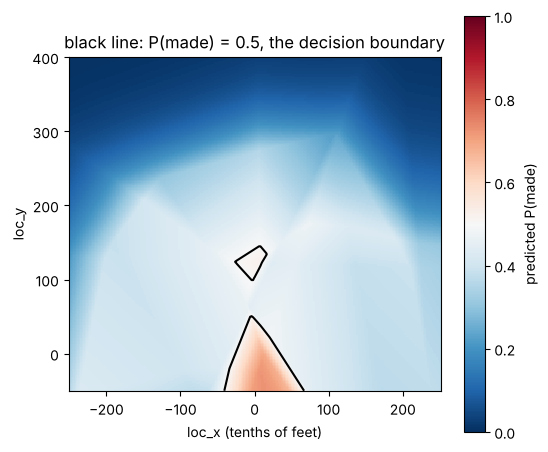

In [12]:
gx, gy = np.meshgrid(np.linspace(-250, 250, 251), np.linspace(-50, 400, 226))
court = np.c_[gx.ravel(), gy.ravel()].astype(np.float32)  # raw coordinates of a grid over the court
with torch.no_grad():
    p_court = model(torch.tensor((court - mu) / sd))[:, 0].numpy().reshape(gx.shape)

plt.figure(figsize=(6, 5.4))
plt.pcolormesh(gx, gy, p_court, cmap="RdBu_r", vmin=0, vmax=1, shading="auto")  # white = 0.5
plt.colorbar(label="predicted P(made)")
plt.contour(gx, gy, p_court, levels=[0.5], colors="black")
plt.gca().set_aspect("equal")
plt.xlabel("loc_x (tenths of feet)")
plt.ylabel("loc_y")
plt.title("black line: P(made) = 0.5, the decision boundary")
plt.show()

## Fold the standardisation into `fc1`

`fc1` computes W (x − μ)/σ + b = (W/σ) x + (b − (W/σ) μ), where "/σ" divides column j of W by σⱼ. So W′ = W/σ and b′ = b − W′μ, and the network gives the same outputs on raw coordinates that it gave on standardised ones. This is exact and legal: the saved model is still only linear layers and activations.

Run this cell once (folding twice breaks the model).

In [13]:
with torch.no_grad():
    p_before = model(X_va_t)[:, 0]  # standardised inputs
    model.fc1.weight /= torch.tensor(sd)  # W' = W / sigma: (8, 2) / (2,) divides column j by sigma_j
    model.fc1.bias -= model.fc1.weight @ torch.tensor(mu)  # b' = b - W' mu
    p_after = model(torch.tensor(X_va))[:, 0]  # RAW inputs now
print(f"max |p_before - p_after| = {(p_before - p_after).abs().max():.1e}")
print("same decision on every validation shot:", bool(((p_before > 0.5) == (p_after > 0.5)).all()))

max |p_before - p_after| = 6.0e-07
same decision on every validation shot: True


## Keep the final Sigmoid?

How the grader turns the output into a label is not published. The evidence: the official baseline ends with `nn.Sigmoid`, so it outputs probabilities, and copies of it scored 0.596–0.600 on the boards. A grader that cut at 0 would have scored every probability model 0.447 ("always made"). So the grader treats the output as a probability and cuts at 0.5.

We keep the Sigmoid. Then "made" ⇔ p > 0.5 ⇔ logit > 0, which is exactly what we validated. What each combination of our output and the grader's rule would score on validation:

In [14]:
with torch.no_grad():
    z_va = model.logits(torch.tensor(X_va))[:, 0].numpy()  # logits on raw coordinates (after folding)
print(f"probability out, grader cuts at 0.5 (our choice): {((z_va > 0) == y_va).mean():.4f}")
print(f"logit out,       grader cuts at 0.5:              {((z_va > 0.5) == y_va).mean():.4f}   (means p > 0.62)")
print(f"probability out, grader cuts at 0:                {y_va.mean():.4f}   (every p > 0: always 'made')")

probability out, grader cuts at 0.5 (our choice): 0.6018
logit out,       grader cuts at 0.5:              0.6002   (means p > 0.62)
probability out, grader cuts at 0:                0.4474   (every p > 0: always 'made')


Dropping the Sigmoid would cost little on this split (the at-rim logits are only just above 0.5), but keeping it reproduces the validated decisions exactly. The one disastrous combination, probabilities with a cut at 0, is ruled out by the baseline's leaderboard score.

## Write the submission and check it like the grader

In [15]:
import zipfile

torch.save(model.state_dict(), SUB_DIR / "submission_dic.pth")
with zipfile.ZipFile(SUB_DIR / "submission.zip", "w") as z:
    z.write(SUB_DIR / "submission_model.py", "submission_model.py")  # top level of the zip, no folders
    z.write(SUB_DIR / "submission_dic.pth", "submission_dic.pth")

In [16]:
import tempfile

# unzip into a fresh, empty folder and load it exactly the way the grader does
check_dir = Path(tempfile.mkdtemp())
with zipfile.ZipFile(SUB_DIR / "submission.zip") as z:
    print("zip contains:", z.namelist())
    z.extractall(check_dir)
graded = load_model_class(check_dir / "submission_model.py")()
graded.load_state_dict(torch.load(check_dir / "submission_dic.pth"), strict=True)  # strict: every name and shape must match
graded.eval()
rules_ok = check_rules(graded)

with torch.no_grad():
    p_raw = graded(torch.tensor(X_va))[:, 0].numpy()  # RAW coordinates, like the grader
print(f"reloaded model on raw coordinates: validation accuracy {((p_raw > 0.5) == y_va).mean():.4f}")
print(f"max |difference| to the notebook's predictions: {np.abs(p_raw - p_va).max():.1e}")
valid = rules_ok and np.abs(p_raw - p_va).max() < 1e-4
print("VALID: legal, and it predicts on raw coordinates what you validated" if valid else "PROBLEM: see the FAILs or the difference above")

zip contains: ['submission_model.py', 'submission_dic.pth']
PASS   no nn.Sequential / ModuleList / ModuleDict
PASS   only nn.Linear and the allowed activations
PASS   no parameters or buffers outside the layers
PASS   at most 3 linear layers
PASS   at most 8 neurons per linear layer
PASS   input size 2, sizes chain up, output size 1
PASS   every module used exactly once, the first is a linear layer
PASS   every activation comes right after a linear layer
PASS   forward is only these modules, no extra maths
PASS   output shape (N, 1)
reloaded model on raw coordinates: validation accuracy 0.6018
max |difference| to the notebook's predictions: 6.0e-07
VALID: legal, and it predicts on raw coordinates what you validated


## What to try next

- **Seeds.** Rerun with 5 split and initialisation seeds and report mean ± std. Differences below 0.005 are ties.
- **Activations.** Tanh, ELU and LeakyReLU land within 0.001 of ReLU with Adam at lr 1e-2.
- **Mini-batches** of 256 for 25 epochs (about the same number of steps) give the same accuracy.
- **Learning rate.** 1e-3 is still under-trained after 2,000 steps (about −0.005); 1.0 diverges.
- **Why scale at all?** SGD with momentum, lr 0.1, on raw inputs collapses to "always miss" (0.553); on standardised inputs it reaches 0.603. Adam hides the problem.
- **Threshold.** To cut at t instead of 0.5, fold it into the last bias: `fc3.bias -= log(t / (1 - t))`. For a well-trained net this gains about 0.
- **More data.** Retrain on all 25,000 shots with the same recipe before the final upload (a tiny gain at most).
- **Leaderboard.** Do not chase it: each board moves by ±0.01 between equally good models.
- **Illegal even if a checker might miss it:** distance or angle computed in `forward()`, μ/σ stored as buffers, `shot_distance` as an input.